# 2. Understand how learning changes a prediction

**Goal:** inspect a gradient and a parameter update, then connect that small example to sinoLLM's training loop. This notebook runs independently.

### Definitions

| Term | Definition |
|---|---|
| Parameter / weight | A trainable number stored by the model |
| Target / label | The correct next token in a training example |
| Loss | A numeric penalty computed from predictions and targets |
| Cross-entropy | For one correct token, `-log(probability assigned to that token)` |
| Gradient | Derivative of loss with respect to a parameter; local sensitivity |
| Backpropagation | Applying the chain rule backward through operations to compute gradients |
| Optimizer | Rule that uses gradients to update parameters |
| Learning rate | Controls update size; too large can destabilize learning |
| Step | One optimizer update using a batch |
| Epoch | One pass through a defined training dataset; random-batch steps are not automatically epochs |
| Inference | Computing predictions without updating parameters |
| Autograd | PyTorch's automatic differentiation system |

A gradient points toward locally increasing loss. Gradient descent moves in the opposite direction. This local estimate does not guarantee that every update improves held-out performance.

In [1]:
from pathlib import Path
import sys

# Find the lesson folder from the notebook folder, mini_llm, or repository root.
candidates = [Path.cwd(), Path.cwd() / "learning_path",
              Path.cwd() / "mini_llm" / "learning_path"]
lesson_dir = next((p.resolve() for p in candidates if (p / "lab.py").is_file()), None)
if lesson_dir is None:
    raise FileNotFoundError("Open this notebook from learning_path, mini_llm, or the repository root.")
if str(lesson_dir) not in sys.path:
    sys.path.insert(0, str(lesson_dir))

import math
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
import lab

torch.set_num_threads(2)
torch.manual_seed(42)
print("Local CPU lesson | PyTorch", torch.__version__)

Matplotlib is building the font cache; this may take a moment.


Local CPU lesson | PyTorch 2.14.1


### A three-choice language model, small enough to inspect
Pretend the only possible next characters are `a`, `b`, and `c`. Start with three equal logits and let `b` be correct. These logits are parameters directly; a real transformer computes logits using many layers.

In [2]:
scores = nn.Parameter(torch.tensor([0.0, 0.0, 0.0]))
target = torch.tensor([1])  # 'b'
optimizer = torch.optim.SGD([scores], lr=0.5)
before = scores.detach().clone()
prob_before = scores.detach().softmax(-1)
loss = F.cross_entropy(scores.unsqueeze(0), target)
optimizer.zero_grad(set_to_none=True)
loss.backward()
gradient = scores.grad.detach().clone()
optimizer.step()
prob_after = scores.detach().softmax(-1)
print("Loss before:", float(loss.detach()))
print("Gradient:", gradient.tolist())
print("Parameters before:", before.tolist())
print("Parameters after: ", scores.detach().tolist())
print("P(correct) before/after:", float(prob_before[1]), float(prob_after[1]))
assert prob_after[1] > prob_before[1]
torch.testing.assert_close(scores.detach(), before - 0.5 * gradient)

Loss before: 1.0986123085021973
Gradient: [0.3333333134651184, -0.6666666865348816, 0.3333333134651184]
Parameters before: [0.0, 0.0, 0.0]
Parameters after:  [-0.1666666567325592, 0.3333333432674408, -0.1666666567325592]
P(correct) before/after: 0.3333333432674408 0.45186275243759155


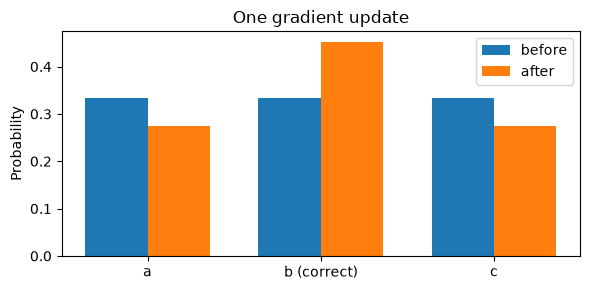

In [3]:
locations = torch.arange(3)
plt.figure(figsize=(6, 3))
plt.bar(locations.numpy()-0.18, prob_before.numpy(), width=0.36, label="before")
plt.bar(locations.numpy()+0.18, prob_after.numpy(), width=0.36, label="after")
plt.xticks(range(3), ["a", "b (correct)", "c"])
plt.ylabel("Probability"); plt.title("One gradient update"); plt.legend()
plt.tight_layout(); plt.show()

### Check one derivative numerically
A **finite difference** estimates the slope by changing one number slightly. This is a teaching check, not how we train large models. `backward()` computes gradients efficiently using the computation graph.

Gradients accumulate by default. `zero_grad()` is necessary between independent steps; forgetting it changes the update rule.

In [4]:
epsilon = 1e-3
plus, minus = before.clone(), before.clone()
plus[1] += epsilon; minus[1] -= epsilon
finite_difference = (F.cross_entropy(plus[None], target) -
                     F.cross_entropy(minus[None], target)) / (2 * epsilon)
print("Autograd:", float(gradient[1]), "finite difference:", float(finite_difference))
assert abs(float(finite_difference - gradient[1])) < 1e-3

Autograd: -0.6666666865348816 finite difference: -0.6666778922080994


### Now use the same loop with a transformer
`train()` and `eval()` control layer behavior such as dropout. `eval()` **does not disable gradients**; use `no_grad()` or `inference_mode()` when appropriate. The optimizer, not `train()`, changes weights.

We record validation before and after optimization. Validation participates in no weight updates. The shared helper uses AdamW, gradient clipping, and random training batches.

Validation loss: 4.735 -> 1.469


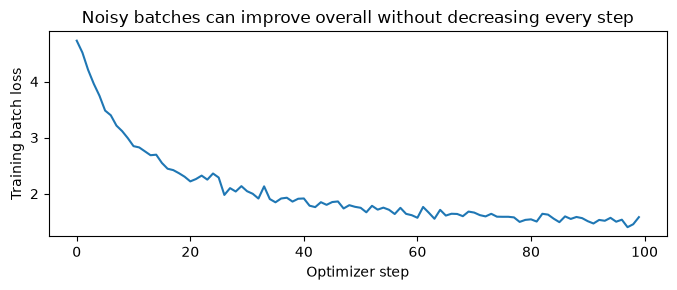

In [5]:
splits = lab.sentence_splits()
train_data, val_data = lab.text_ids(splits["train"]), lab.text_ids(splits["val"])
torch.manual_seed(42)
model = lab.SinoLM()
validation_before = lab.evaluate(model, val_data)
losses = lab.train_lm(model, train_data, steps=100)
validation_after = lab.evaluate(model, val_data)
print(f"Validation loss: {validation_before:.3f} -> {validation_after:.3f}")
assert validation_after < validation_before
plt.figure(figsize=(7, 3))
plt.plot(losses); plt.xlabel("Optimizer step"); plt.ylabel("Training batch loss")
plt.title("Noisy batches can improve overall without decreasing every step")
plt.tight_layout(); plt.show()

### Check your understanding

Does `model.eval()` prevent training? Does a lower training loss prove better answers?

<details><summary>Suggested answer — try first</summary>

No. `eval()` changes layer behavior but still permits gradient computation. Lower training loss demonstrates better fit to the measured training data; validation, task evaluation and actual outputs are separate evidence.

</details>

### Your exercises
1. Try learning rates 0.05 and 0.5 in the three-choice example. Inspect probability changes.
2. Deliberately omit `zero_grad()` for two scalar-model steps; explain the resulting accumulation, then restore it.
3. Find `loss.backward()` and `optimizer.step()` inside `lab.train_lm`. Explain their separate jobs.

**Completion criterion:** identify the exact line that computes gradients and the exact line that changes parameters.

Reference: [PyTorch CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html). Next: [03 — Rebuild attention](03_rebuild_attention.ipynb).